In [1]:
from pathlib import Path 
import sys 

import numpy as np 
import pandas as pd 
from PIL import Image 
import matplotlib.pyplot as plt 

In [2]:
PROJECT_ROOT = Path.cwd() 

if PROJECT_ROOT.name == "notebooks": 
    PROJECT_ROOT = PROJECT_ROOT.parent 

sys.path.insert(0, str(PROJECT_ROOT)) 

from src.embedder import Embedder 

/Users/aob/AOB/CS/Projects/clip-semantic-search/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1101 15:39:13.066000 74322 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [4]:
embeddings_path = (
    PROJECT_ROOT 
    / "data" 
    / "embeddings" 
    / "abo_image_embeddings.npy"
)

metadata_path = (
    PROJECT_ROOT 
    / "data" 
    / "embeddings" 
    / "abo_image_metadata.csv"
)

image_embeddings = np.load(embeddings_path) 
metadata = pd.read_csv(metadata_path) 

print("Embeddings:", image_embeddings.shape) 
print("Metadata rows:", len(metadata)) 

Embeddings: (1000, 512)
Metadata rows: 1000


In [5]:
embedder = Embedder() 

print("Device:", embedder.device)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 68244.67it/s]


Device: mps


In [6]:
# Search one query 

query = "a black handbag" 

query_embedding = embedder.embed_text(query) 

print("Query embedding shape:", query_embedding.shape) 
print("Query embedding norm:", np.linalg.norm(query_embedding) )

Query embedding shape: (512,)
Query embedding norm: 1.0000001


In [7]:
# Calc similarities 

similarities = image_embeddings @ query_embedding 

print("Similarity scores shape:", similarities.shape) 
print("Highest score:", similarities.max()) 
print("Lowest score:", similarities.min())

Similarity scores shape: (1000,)
Highest score: 0.3064394
Lowest score: 0.11345471


In [8]:
# Top five results 

top_k = 5 

top_indices = np.argsort(similarities)[::-1][:top_k] 

results = metadata.iloc[top_indices].copy() 
results['similarity'] = similarities[top_indices] 

results[
    [
        "item_id",
        "product_type",
        "title",
        "image_path",
        "similarity",
    ]
]

,item_id,product_type,title,image_path,similarity
941,B081HMLLBR,HANDBAG,Nia & Nicole Women's Handbag (Navy Blue),data/ABO/abo-images-small/images/small/0f/0fa0...,0.306439
37,B000R5H79K,CELLULAR_PHONE_CASE,Rivet The Wrap Fashion Case for Mobile Phones,data/ABO/abo-images-small/images/small/5c/5c4c...,0.304861
952,B07WRJFTRK,HANDBAG,Flavia Women's Handbag (Black),data/ABO/abo-images-small/images/small/c4/c427...,0.301635
912,B06X17B2N4,HANDBAG,The Lovely bolsa Co. - Bolera de nailon con as...,data/ABO/abo-images-small/images/small/ad/add5...,0.296398
911,B08F9ZWWXP,HANDBAG,WindTook Small Crossbody Bag for Women Shoulde...,data/ABO/abo-images-small/images/small/f9/f9bd...,0.293936


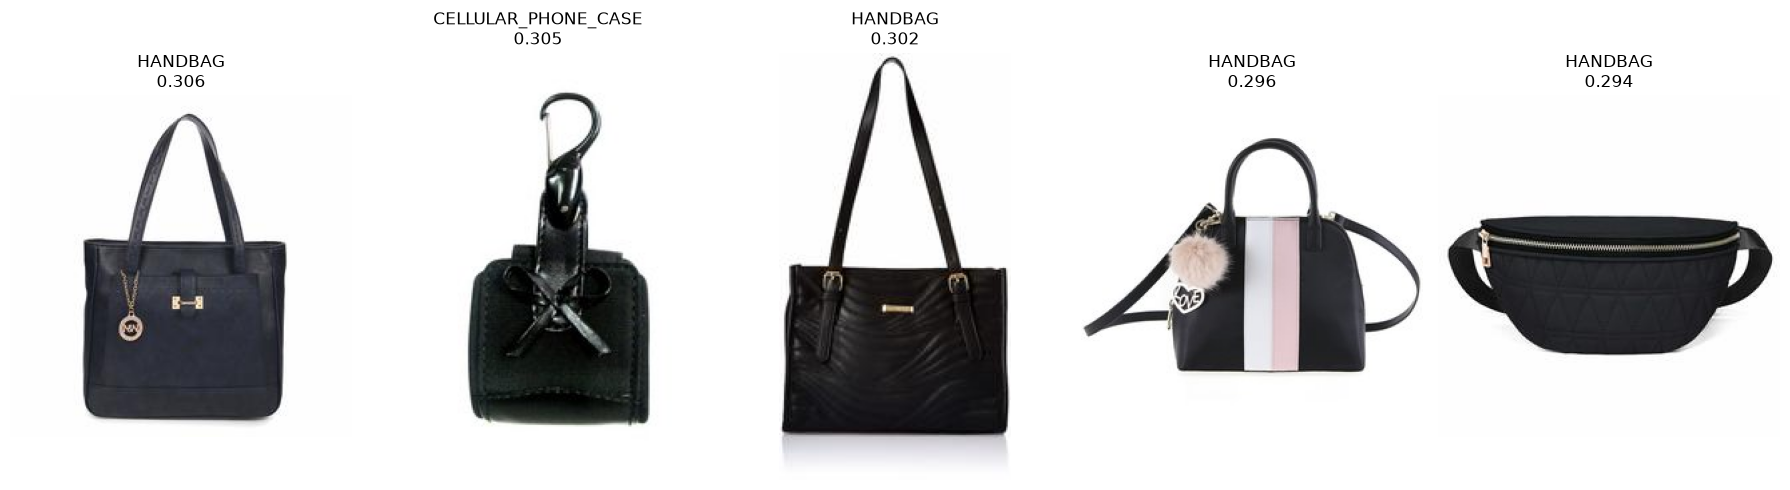

In [10]:
# Display images 

fig, axes = plt.subplots(1, top_k, figsize=(18, 5)) 

for axis, (_, result) in zip(axes, results.iterrows()): 
    image_path = PROJECT_ROOT / result["image_path"] 

    with Image.open(image_path) as image: 
        axis.imshow(image.convert("RGB"))

    axis.set_title(
        f"{result['product_type']}\n" 
        f"{result['similarity']:.3f}" 
    )
    axis.axis("off")

plt.tight_layout() 
plt.show() 

In [11]:
def search_images(query: str, top_k: int = 5) -> pd.DataFrame: 
    query_embedding = embedder.embed_text(query) 
    similarities = image_embeddings @ query_embedding 

    top_indices = np.argsort(similarities)[::-1][:top_k] 

    results = metadata.iloc[top_indices].copy() 
    results['similarity'] = similarities[top_indices] 

    return results 

In [12]:
queries = [
    "a black handbag",
    "comfortable running shoes",
    "a blue phone case",
    "modern furniture",
    "home decor",
]

for query in queries:
    print(f"\nQuery: {query}")

    results = search_images(query, top_k=5)

    print(
        results[
            ["product_type", "title", "similarity"]
        ].to_string(index=False)
    )


Query: a black handbag
       product_type                                                                                                                                                                         title  similarity
            HANDBAG                                                                                                                                      Nia & Nicole Women's Handbag (Navy Blue)    0.306439
CELLULAR_PHONE_CASE                                                                                                                                 Rivet The Wrap Fashion Case for Mobile Phones    0.304861
            HANDBAG                                                                                                                                                Flavia Women's Handbag (Black)    0.301635
            HANDBAG The Lovely bolsa Co. - Bolera de nailon con asa superior a rayas en contraste con pompones de piel sintética para mujer, Bolero de n

In [13]:
metadata["product_type"].value_counts() 

product_type
CELLULAR_PHONE_CASE         100
SHOES                       100
GROCERY                     100
HOME                        100
HOME_BED_AND_BATH           100
HOME_FURNITURE_AND_DECOR    100
CHAIR                       100
BOOT                        100
SANDAL                      100
HANDBAG                     100
Name: count, dtype: int64

In [14]:
results["product_type"].value_counts() 

product_type
HOME                        3
HOME_FURNITURE_AND_DECOR    2
Name: count, dtype: int64